In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Water Quality Modeling Preparation

## Objective

This notebook prepares Kerala water-quality monitoring data for machine-learning analysis.

The preparation includes defining an indicator-based prediction target, selecting relevant features, handling missing values, encoding categorical variables, and splitting the data into training and testing sets.

The prediction task will focus on identifying observations exceeding a selected water-quality indicator threshold. It will not represent certified drinking-water potability.

In [2]:
df = pd.read_csv("../data/kerala_water_quality_preprocessed.csv")

df.shape

(1155, 21)

In [3]:
df.columns.tolist()

['_id',
 'SlNo',
 'Station',
 'Agency',
 'State_LGD_Code',
 'State',
 'District_LGD_Code',
 'District',
 'Tehsil',
 'River',
 'Basin',
 'Tributary',
 'Subtributary',
 'SubSubtributary',
 'Local_River',
 'Latitude',
 'Longitude',
 'Data_Acquisition_Time',
 'Biochemical_Oxygen_Demand_(mg/L)',
 'Fecal_Coliform_(MPN/100mL)',
 'Total_Coliform_(MPN/100mL)']

In [4]:
df["Fecal_Coliform_(MPN/100mL)"].notna().sum()

np.int64(883)

In [5]:
df_model = df.dropna(subset=["Fecal_Coliform_(MPN/100mL)"]).copy()

df_model["FC_Exceedance"] = (
    df_model["Fecal_Coliform_(MPN/100mL)"] > 2500
).astype(int)

df_model["FC_Exceedance"].value_counts()

FC_Exceedance
0    820
1     63
Name: count, dtype: int64

In [6]:
df_model["Data_Acquisition_Time"] = pd.to_datetime(
    df_model["Data_Acquisition_Time"]
)

df_model["Month"] = df_model["Data_Acquisition_Time"].dt.month

df_model[["Month", "FC_Exceedance"]].head()

,Month,FC_Exceedance
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0


In [7]:
features = [
    "Biochemical_Oxygen_Demand_(mg/L)",
    "Total_Coliform_(MPN/100mL)",
    "Latitude",
    "Longitude",
    "Month"
]

X = df_model[features]
y = df_model["FC_Exceedance"]

X.shape, y.shape

((883, 5), (883,))

In [8]:
X.isna().sum()

Biochemical_Oxygen_Demand_(mg/L)    416
Total_Coliform_(MPN/100mL)          824
Latitude                              0
Longitude                             0
Month                                 0
dtype: int64

## Modeling Decisions and Rationale

### Prediction Target

The target variable is `FC_Exceedance`, derived from Fecal Coliform measurements using the selected bathing-water maximum permissible benchmark of 2,500 MPN/100mL.

- 0: FC ≤ 2,500 MPN/100mL
- 1: FC > 2,500 MPN/100mL

This is a threshold-derived indicator target, not a verified potability label.

### Feature Selection

The selected input features are:

- Biochemical Oxygen Demand (BOD)
- Latitude
- Longitude
- Month

Fecal Coliform is excluded from the input features because it directly defines the target, which would cause target leakage. Total Coliform is excluded because 824 of the 883 target-valid observations have missing TC measurements.

### Missing-Value Handling

BOD contains 416 missing values among the 883 target-valid observations. These values will be imputed using the median calculated from the training data.

Latitude, longitude, and month have no missing values.

### Model Selection

Two classification algorithms will be trained and compared:

1. K-Nearest Neighbors (KNN): predicts a class based on nearby training observations.
2. Logistic Regression: estimates the probability of belonging to the exceedance class using a logistic function.

Both models will use the same training and testing data to support a fair comparison.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape, y_train.value_counts(), y_test.value_counts()

((706, 5),
 (177, 5),
 FC_Exceedance
 0    656
 1     50
 Name: count, dtype: int64,
 FC_Exceedance
 0    164
 1     13
 Name: count, dtype: int64)

## Train-Test Split

The target-valid dataset was divided into:

- 80% training data (706 observations)
- 20% testing data (177 observations)

Stratified splitting was used to preserve the class proportions of the FC exceedance target in both sets.

A fixed random state of 42 was used to ensure reproducibility.

The test set will remain separate from model training and will be used for final performance evaluation.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [11]:
numeric_features = [
    "Biochemical_Oxygen_Demand_(mg/L)",
    "Latitude",
    "Longitude",
    "Month"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        )
    ]
)

### Difference Between Data Cleaning and Model Preprocessing

Notebook 03 performed general dataset cleaning, including date conversion, column standardization, removal of entirely missing COD, and handling invalid negative measurements.

Notebook 05 performs model-specific preprocessing:

- Missing BOD values are imputed using the median calculated from training data.
- Numerical features are standardized using StandardScaler.
- The preprocessing pipeline is fitted only on training data to prevent data leakage.

This separation preserves the cleaned dataset while preparing suitable inputs for machine-learning algorithms.

In [12]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data:", X_train_processed.shape)
print("Testing data:", X_test_processed.shape)

print("Missing values in training:", np.isnan(X_train_processed).sum())
print("Missing values in testing:", np.isnan(X_test_processed).sum())

Training data: (706, 4)
Testing data: (177, 4)
Missing values in training: 0
Missing values in testing: 0


In [13]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_processed, y_train)

knn_predictions = knn_model.predict(X_test_processed)

print("KNN model training completed.")

KNN model training completed.


In [14]:
from sklearn.metrics import accuracy_score

knn_accuracy = accuracy_score(y_test, knn_predictions)

print("KNN Accuracy:", round(knn_accuracy * 100, 2), "%")

KNN Accuracy: 95.48 %


In [15]:
print(classification_report(
    y_test,
    knn_predictions,
    target_names=["Within Threshold", "FC Exceedance"]
))

                  precision    recall  f1-score   support

Within Threshold       0.96      0.99      0.98       164
   FC Exceedance       0.86      0.46      0.60        13

        accuracy                           0.95       177
       macro avg       0.91      0.73      0.79       177
    weighted avg       0.95      0.95      0.95       177



In [16]:
knn_cm = confusion_matrix(y_test, knn_predictions)

print(knn_cm)

[[163   1]
 [  7   6]]


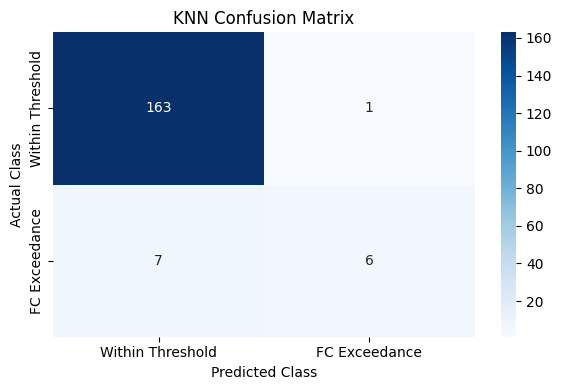

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

sns.heatmap(
    knn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Within Threshold", "FC Exceedance"],
    yticklabels=["Within Threshold", "FC Exceedance"]
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

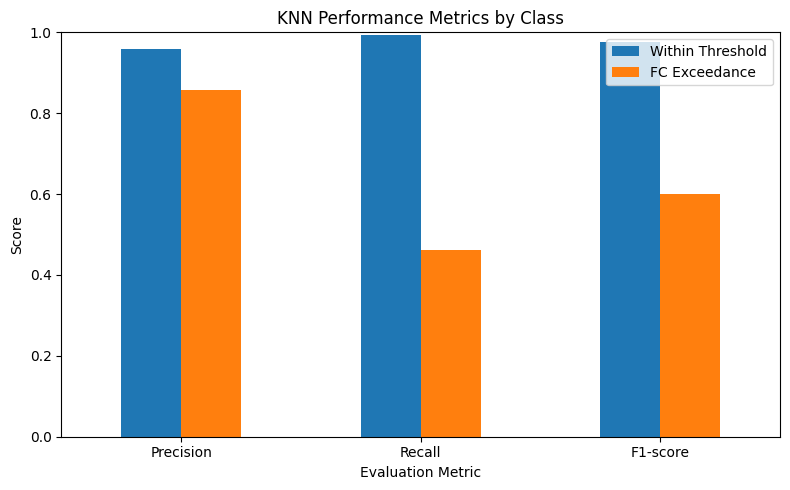

In [18]:
knn_report = classification_report(
    y_test,
    knn_predictions,
    output_dict=True
)

knn_metrics = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-score"],
    "Within Threshold": [
        knn_report["0"]["precision"],
        knn_report["0"]["recall"],
        knn_report["0"]["f1-score"]
    ],
    "FC Exceedance": [
        knn_report["1"]["precision"],
        knn_report["1"]["recall"],
        knn_report["1"]["f1-score"]
    ]
})

knn_metrics.set_index("Metric").plot(
    kind="bar",
    figsize=(8, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("KNN Performance Metrics by Class")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.tight_layout()
plt.show()

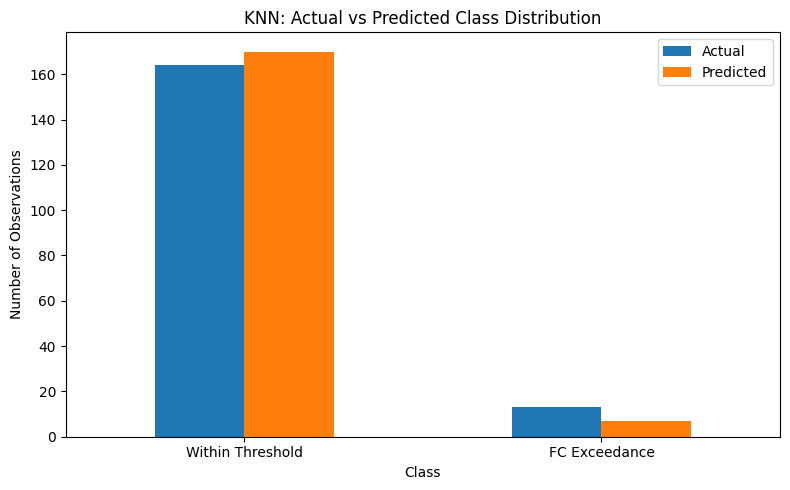

In [19]:
comparison = pd.DataFrame({
    "Actual": y_test.value_counts().sort_index(),
    "Predicted": pd.Series(knn_predictions).value_counts().sort_index()
})

comparison.index = ["Within Threshold", "FC Exceedance"]

comparison.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("KNN: Actual vs Predicted Class Distribution")
plt.ylabel("Number of Observations")
plt.xlabel("Class")
plt.legend()
plt.tight_layout()
plt.show()

## KNN Model – Observations

The K-Nearest Neighbors (KNN) classifier was trained using 5 nearest neighbors and evaluated on 177 test observations.

### Performance Summary

- Accuracy: 95.48%
- Precision for FC Exceedance: 0.86
- Recall for FC Exceedance: 0.46
- F1-score for FC Exceedance: 0.60

### Confusion Matrix Analysis

The model correctly classified 163 observations within the selected threshold and 6 FC exceedances. It incorrectly classified 7 exceedances as within-threshold observations and produced 1 false positive.

### Visualization Observations

- The confusion matrix heatmap shows strong classification performance for the within-threshold class but weaker detection of exceedances.
- The performance metrics chart highlights the lower recall and F1-score of the exceedance class.
- The actual-versus-predicted distribution chart shows that KNN predicted 7 exceedances compared with 13 actual exceedances.

### Overall Interpretation

KNN achieved high overall accuracy, but its ability to detect FC exceedances was limited. The class imbalance in the dataset influences its performance, making accuracy alone insufficient to assess the model.

The model's results should be interpreted as predicting the selected FC threshold-based indicator, not certified water potability.

In [20]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

logistic_predictions = logistic_model.predict(X_test_processed)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [21]:
logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

print("Logistic Regression Accuracy:",
      round(logistic_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 95.48 %


In [22]:
print(classification_report(
    y_test,
    logistic_predictions,
    target_names=["Within Threshold", "FC Exceedance"]
))

                  precision    recall  f1-score   support

Within Threshold       0.95      1.00      0.98       164
   FC Exceedance       1.00      0.38      0.56        13

        accuracy                           0.95       177
       macro avg       0.98      0.69      0.77       177
    weighted avg       0.96      0.95      0.95       177



In [23]:
logistic_cm = confusion_matrix(y_test, logistic_predictions)

print(logistic_cm)

[[164   0]
 [  8   5]]


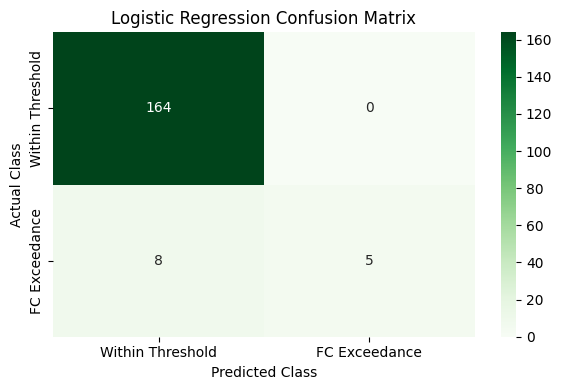

In [24]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Within Threshold", "FC Exceedance"],
    yticklabels=["Within Threshold", "FC Exceedance"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

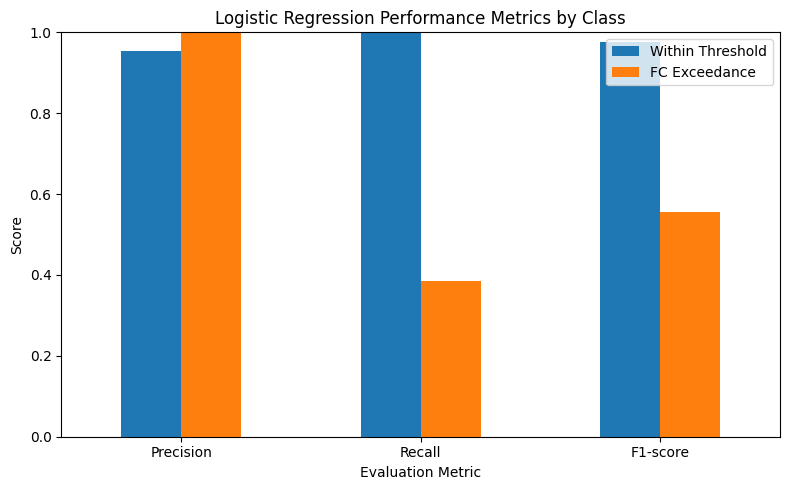

In [25]:
logistic_report = classification_report(
    y_test,
    logistic_predictions,
    output_dict=True
)

logistic_metrics = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-score"],
    "Within Threshold": [
        logistic_report["0"]["precision"],
        logistic_report["0"]["recall"],
        logistic_report["0"]["f1-score"]
    ],
    "FC Exceedance": [
        logistic_report["1"]["precision"],
        logistic_report["1"]["recall"],
        logistic_report["1"]["f1-score"]
    ]
})

logistic_metrics.set_index("Metric").plot(
    kind="bar",
    figsize=(8, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Logistic Regression Performance Metrics by Class")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.tight_layout()
plt.show()

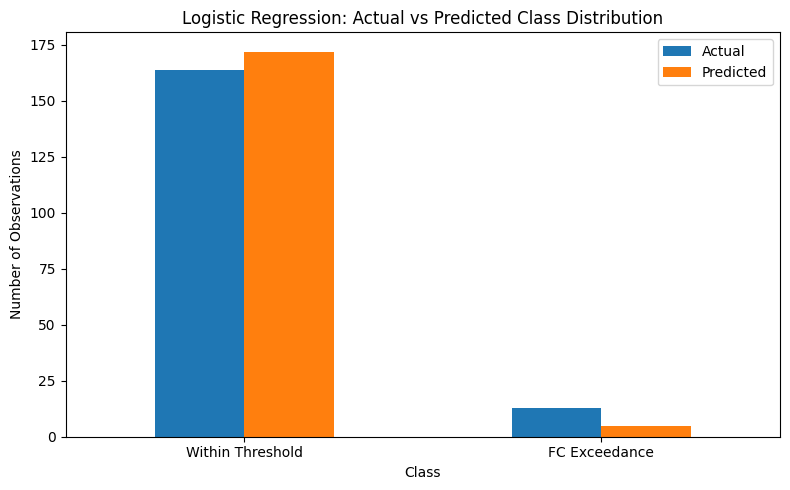

In [26]:
comparison_logistic = pd.DataFrame({
    "Actual": y_test.value_counts().sort_index(),
    "Predicted": pd.Series(logistic_predictions).value_counts().sort_index()
})

comparison_logistic.index = [
    "Within Threshold",
    "FC Exceedance"
]

comparison_logistic.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Logistic Regression: Actual vs Predicted Class Distribution")
plt.ylabel("Number of Observations")
plt.xlabel("Class")
plt.legend()
plt.tight_layout()
plt.show()

## Logistic Regression – Observations

Logistic Regression was trained and evaluated using the same training and testing datasets as KNN.

### Performance Summary

- Accuracy: 95.48%
- Precision for FC Exceedance: 1.00
- Recall for FC Exceedance: 0.38
- F1-score for FC Exceedance: 0.56

### Confusion Matrix Analysis

The model correctly classified all 164 observations within the selected FC threshold and 5 FC exceedances. It produced no false positives but incorrectly classified 8 actual exceedances as within-threshold observations.

### Visualization Observations

- The confusion matrix heatmap shows perfect classification of within-threshold observations and no false positives.
- The performance metrics chart highlights the high precision but comparatively low recall for FC exceedances.
- The actual-versus-predicted distribution chart shows that Logistic Regression predicted 5 exceedances compared with 13 actual exceedances.

### Overall Interpretation

Logistic Regression achieved high overall accuracy but demonstrated limited sensitivity toward FC exceedances. Its high precision indicates that predicted exceedances were correct in this test set, but it missed several actual exceedances.

The results represent prediction of the selected FC threshold-based indicator and do not establish drinking-water potability.

In [27]:
#comparison
model_comparison = pd.DataFrame({
    "Model": ["KNN", "Logistic Regression"],
    "Accuracy": [
        knn_accuracy,
        logistic_accuracy
    ],
    "FC Exceedance Precision": [
        knn_report["1"]["precision"],
        logistic_report["1"]["precision"]
    ],
    "FC Exceedance Recall": [
        knn_report["1"]["recall"],
        logistic_report["1"]["recall"]
    ],
    "FC Exceedance F1-score": [
        knn_report["1"]["f1-score"],
        logistic_report["1"]["f1-score"]
    ]
})

model_comparison

,Model,Accuracy,FC Exceedance Precision,FC Exceedance Recall,FC Exceedance F1-score
0,KNN,0.954802,0.857143,0.461538,0.600000
1,Logistic Regression,0.954802,1.000000,0.384615,0.555556


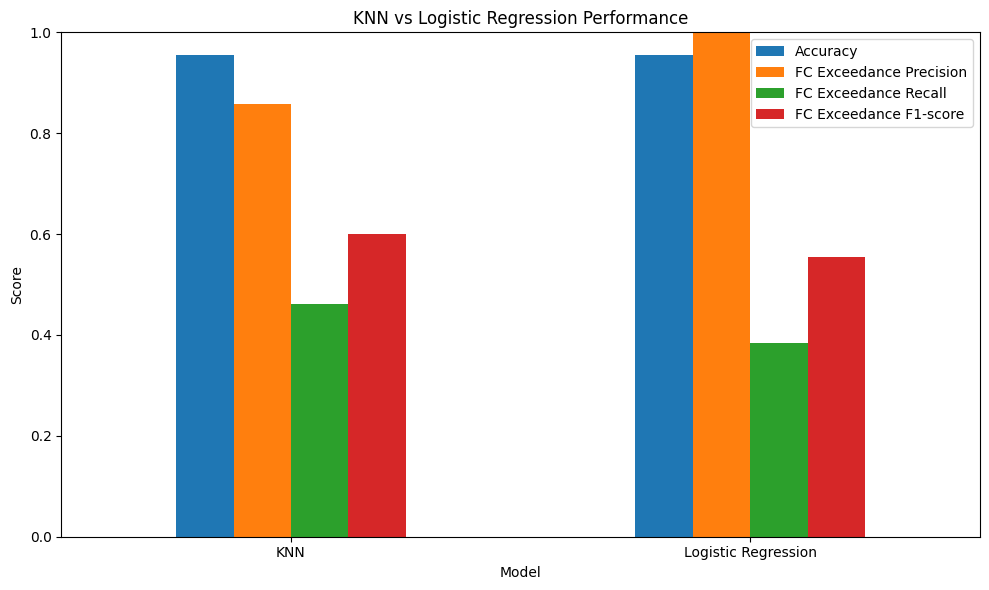

In [28]:
model_comparison.set_index("Model")[
    [
        "Accuracy",
        "FC Exceedance Precision",
        "FC Exceedance Recall",
        "FC Exceedance F1-score"
    ]
].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("KNN vs Logistic Regression Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

## Model Comparison – Observations

KNN and Logistic Regression were evaluated using the same training and testing datasets.

### Comparative Results

Both models achieved an accuracy of 95.48%.

- KNN achieved an FC Exceedance precision of 85.71%, recall of 46.15%, and F1-score of 0.60.
- Logistic Regression achieved an FC Exceedance precision of 100%, recall of 38.46%, and F1-score of 0.56.

### Comparison Graph Observations

The comparison graph shows that:

- Both models have identical accuracy.
- KNN has higher FC Exceedance recall and F1-score.
- Logistic Regression has higher FC Exceedance precision.
- KNN detects more actual exceedances than Logistic Regression.
- Both models have limited recall for the minority exceedance class.

### Conclusion

KNN performed comparatively better in identifying FC exceedances because it achieved higher recall and F1-score. Logistic Regression showed higher precision but missed more actual exceedances.

Although both models achieved high accuracy, the minority-class results indicate that neither model is sufficiently reliable for detecting all FC exceedances.

These models predict a threshold-derived FC indicator and should not be interpreted as certifying water potability or drinking-water safety.

## Final Conclusion

This notebook prepared the Kerala water-quality dataset for machine-learning classification and evaluated K-Nearest Neighbors (KNN) and Logistic Regression.

The FC Exceedance target was constructed using the selected fecal coliform threshold of 2,500 MPN/100mL. Missing BOD values were imputed using training-data median values, and numerical features were standardized without data leakage.

Both models achieved 95.48% accuracy. KNN achieved a higher FC Exceedance recall and F1-score, while Logistic Regression achieved higher precision. However, both models struggled to identify all exceedance observations because of the imbalanced target distribution.

The results demonstrate the importance of evaluating classification models using precision, recall, F1-score, and confusion matrices rather than accuracy alone.

The predictions represent a threshold-based fecal coliform indicator and do not establish drinking-water potability or safety.